### REFERENCES
 * https://chatgpt.com

# Problem framing

> ## Main goal
 > Predict whether an email is spam or not in order to support automated email filtering.

> ## Value
 > * Reduce unwanted emails in inboxes
 > * Protect users from phishing and malware
 > * Improve productivity by minimizing time spent on spam
 > * Enable consistent and scalable email filtering
 > * Support real-time automated decisions on incoming emails
> 
> Even a small improvement in spam detection can significantly reduce exposure to phishing, malware, and irrelevant messages at scale.

> ## Can we solve it without ML?
> Rule-based systems (e.g., block emails with “free”, “win”, or suspicious links) exist, but ML allows:
> 
> * Capturing complex patterns and combinations of words that indicate spam
> * Modeling non-linear relationships between features
> * Adapting automatically to new spam techniques
> * Improving precision and recall compared to simple keyword rules



> ## Do we have enough quality data?
> We must verify:
> * Emails are complete and correctly labeled
> * No missing or corrupted values

> The dataset contains thousands of labeled emails, which is enough for supervised learning.
>
> Potentially predictors include:
> * Patterns in word usage (e.g., repetitive phrases common in spam)
> * Length of the email

> ## Technical formulation
> 
> We will train a spam classifier that assigns a label (spam or not spam) to each email based on its features.
> This is a:
> 
> * Supervised learning problem
> * Binary classification
> * Probabilistic prediction task

> The target indicates spam (1) or non-spam (0). Performance can be measured via:
> * ROC-AUC: How well the classifier ranks spam above non-spam
> * F1-score for spam class: Balances precision (few false positives) and recall (few missed spam).
> * Accuracy is secondary, especially if the dataset is imbalanced

> ### What are the Input and Output?
> Input (X):
> 
> Each row represents an email. Features can include:
> 
> * Cleaned text (lowercase, punctuation removed)
> * TF-IDF vector of words or n-grams
> * Email length (number of words or characters)

>
> Output (y):
> 
> Binary label:
> 
> * 0 → Not spam
> * 1 → Spam

# Data collection

> ## Dataset size and sampling strategy
> The original **emails.csv** dataset will be split into **training** and **test** sets, using 80% of the data for training and 20% for testing.
> Within the training set, we will apply k-fold cross-validation to:

> * Test model performance on multiple folds of the data
> * Reduce variance due to random splitting
> * Compare different classifiers
> * Select the model and hyperparameters that consistently perform best across folds

> After cross-validation, the chosen model will be trained on the full training set and finally evaluated on the held-out test set to measure performance on unseen data.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import re
import string
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [2]:
emails_df = pd.read_csv("emails.csv")

> ## Data features and label

In [3]:
emails_df.head()

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [4]:
emails_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [5]:
print(f"Types: {emails_df.dtypes}") # features types

Types: text    object
spam     int64
dtype: object


> ## Data quality verification

In [6]:
emails_df.describe()

,spam
count,5728.000000
mean,0.238827
std,0.426404
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


Shape train: (5728, 2)

Data spam distribution :
 spam
0    4360
1    1368
Name: count, dtype: int64 spam
0    0.761173
1    0.238827
Name: proportion, dtype: float64


<Axes: xlabel='spam', ylabel='Count'>

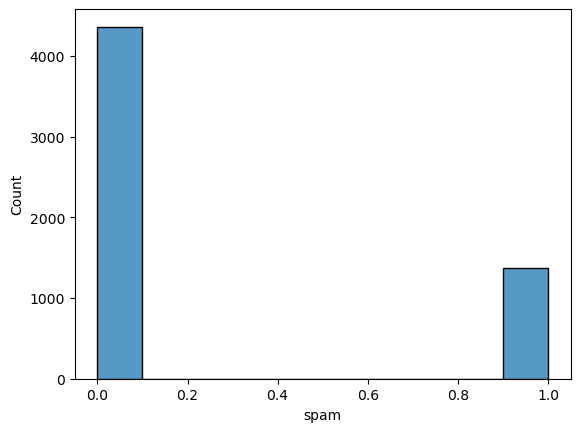

In [7]:
print(f"Shape train: {emails_df.shape}")
print("\nData spam distribution :\n", emails_df['spam'].value_counts(normalize=False), emails_df['spam'].value_counts(normalize=True))
sns.histplot(emails_df["spam"], bins=10)

# Data wrangling

> ## Data transformation pipeline

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer



def extract_numeric_features(df):
    text_col = df["text"]
    features = pd.DataFrame()
    
    # Longueur
    features["num_chars"] = text_col.apply(len)
    features["num_words"] = text_col.apply(lambda x: len(x.split()))
    features["num_sentences"] = text_col.apply(lambda x: len(re.findall(r'[.!?]+', x)))
    
    # Ponctuation
    features["num_exclamation"] = text_col.apply(lambda x: x.count("!"))
    features["num_question"] = text_col.apply(lambda x: x.count("?"))
    features["num_punctuation"] = text_col.apply(lambda x: sum(1 for c in x if c in string.punctuation))
    
    # Majuscules
    features["uppercase_ratio"] = text_col.apply(lambda x: sum(1 for c in x if c.isupper()) / len(x) if len(x) > 0 else 0)
    
    # Liens
    # features["num_links"] = text_col.apply(lambda x: len(re.findall(r'http[s]?://|www\.', x)))
    # Commented it because Null
    
    # Chiffres
    features["num_digits"] = text_col.apply(lambda x: sum(1 for c in x if c.isdigit()))
    
    # Caractères spéciaux restants (tout ce qui n’est pas lettre, chiffre ou espace)
    features["num_special_chars"] = text_col.apply(lambda x: sum(1 for c in x if not c.isalnum() and not c.isspace()))
    
    return features
    

numeric_transformer = Pipeline([
    ("selector", FunctionTransformer(extract_numeric_features, validate=False)),
    ("scaler", StandardScaler())
])

text_transformer = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, max_features=3000, ngram_range=(1,2)))
])

preprocessor = ColumnTransformer([
    ('text', text_transformer, 'text'),
    ('numeric', numeric_transformer, ['text'])
])

pipeline = Pipeline([
    ('preprocessor', preprocessor, )
])

X = emails_df[['text']]
y = emails_df['spam']



X_train_brut, X_test_brut, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train_brut, X_val_brut, y_train, y_val = train_test_split(
    X_train_brut, y_train, test_size=0.2, random_state=42, stratify=y_train
)

pipeline.fit(X_train_brut)

X_train = pipeline.transform(X_train_brut).toarray()
X_val = pipeline.transform(X_val_brut).toarray()
X_test = pipeline.transform(X_test_brut).toarray()

# Data analysis

In [9]:
features = extract_numeric_features(emails_df)
df = pd.concat([emails_df, features], axis=1)
features_to_plot = ['num_words', 'num_chars', 'num_digits', 'uppercase_ratio', 'num_question', 'num_punctuation', 'num_exclamation', 'num_special_chars']

df.corr(numeric_only=True)

,spam,num_chars,num_words,num_sentences,num_exclamation,num_question,num_punctuation,uppercase_ratio,num_digits,num_special_chars
spam,1.000000,-0.065686,-0.080818,-0.013835,0.298356,-0.019374,-0.107146,0.085938,-0.094670,-0.107642
num_chars,-0.065686,1.000000,0.986005,0.595996,0.268999,0.056916,0.768144,-0.313552,0.497784,0.770801
num_words,-0.080818,0.986005,1.000000,0.660144,0.286927,0.086835,0.853976,-0.321441,0.579437,0.855987
num_sentences,-0.013835,0.595996,0.660144,1.000000,0.256019,0.616016,0.704758,-0.200775,0.627134,0.705578
num_exclamation,0.298356,0.268999,0.286927,0.256019,1.000000,0.001829,0.255948,-0.068918,0.135554,0.255230
num_question,-0.019374,0.056916,0.086835,0.616016,0.001829,1.000000,0.202581,-0.031484,0.034210,0.203588
num_punctuation,-0.107146,0.768144,0.853976,0.704758,0.255948,0.202581,1.000000,-0.284992,0.627437,0.999871
uppercase_ratio,0.085938,-0.313552,-0.321441,-0.200775,-0.068918,-0.031484,-0.284992,1.000000,-0.200817,-0.285005
num_digits,-0.094670,0.497784,0.579437,0.627134,0.135554,0.034210,0.627437,-0.200817,1.000000,0.626726
num_special_chars,-0.107642,0.770801,0.855987,0.705578,0.255230,0.203588,0.999871,-0.285005,0.626726,1.000000


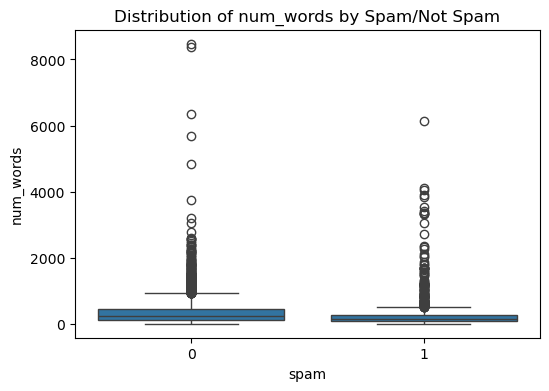

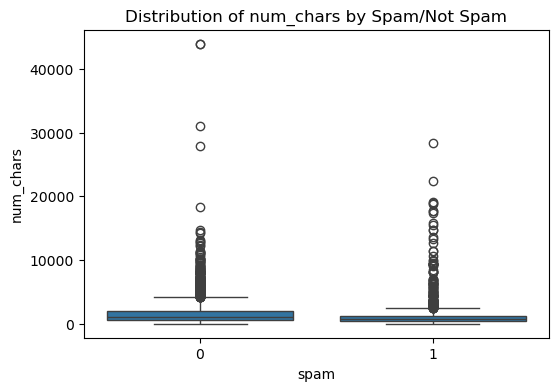

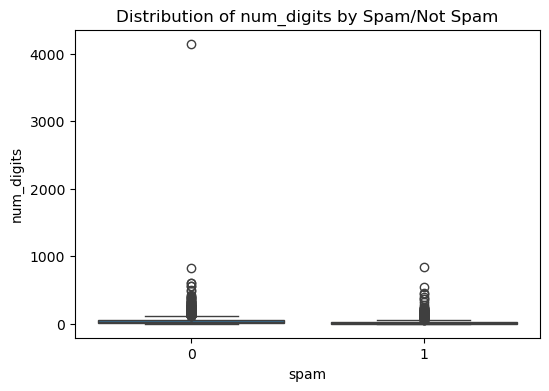

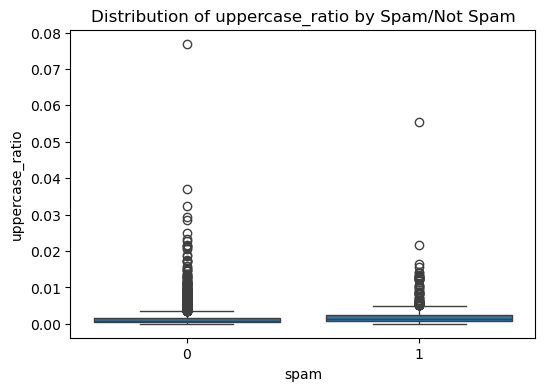

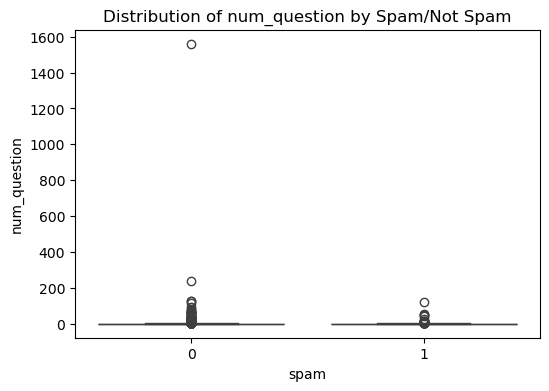

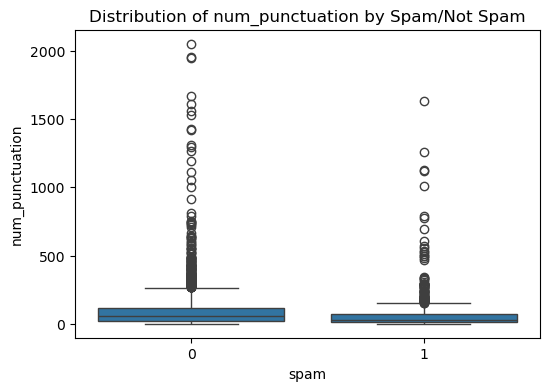

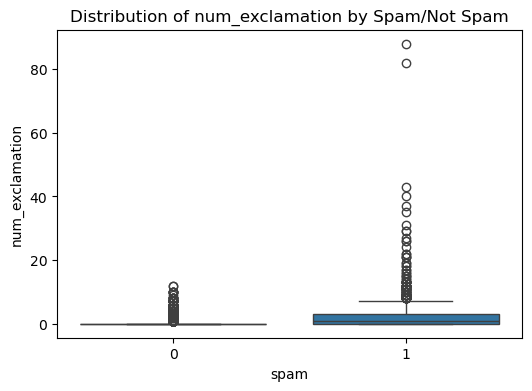

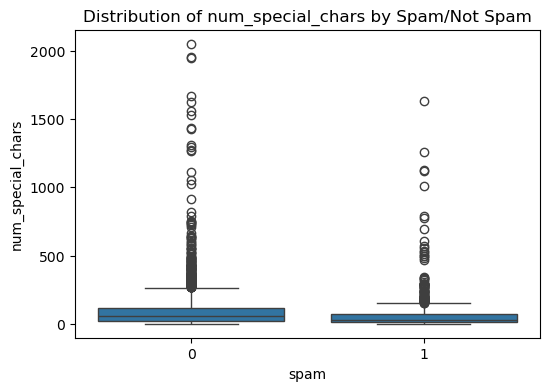

In [10]:
for feat in features_to_plot:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='spam', y=feat, data=df)
    plt.title(f'Distribution of {feat} by Spam/Not Spam')
    plt.show()

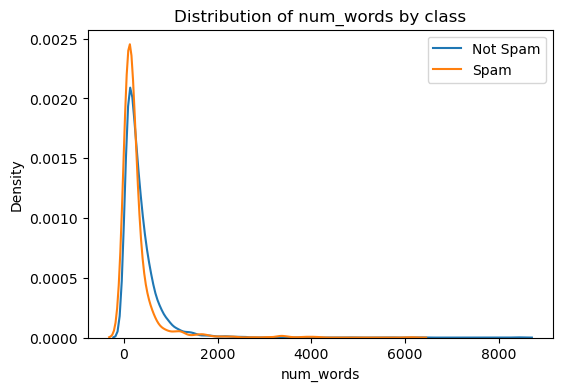

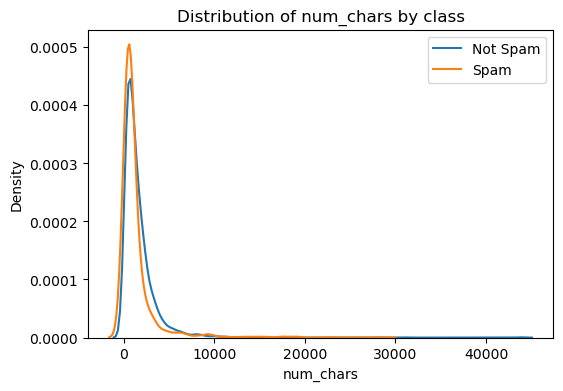

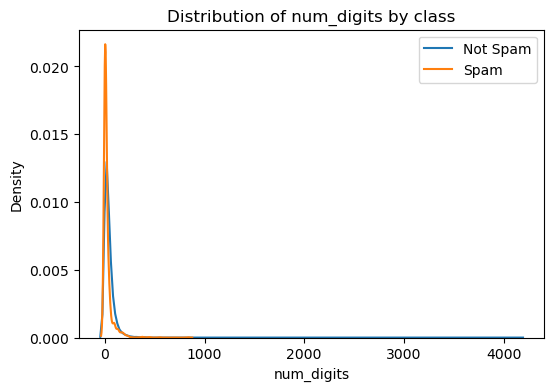

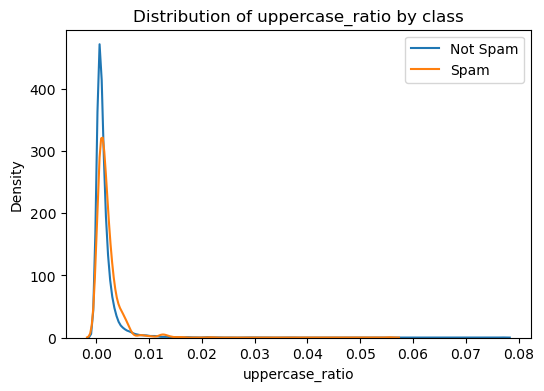

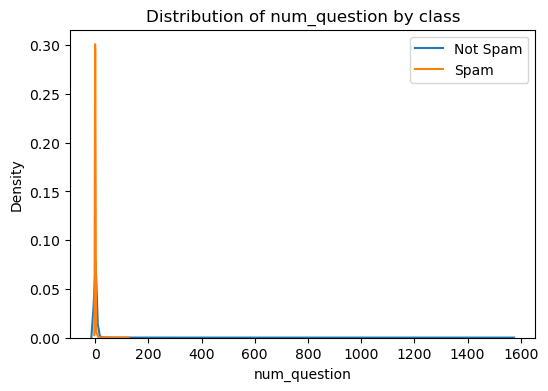

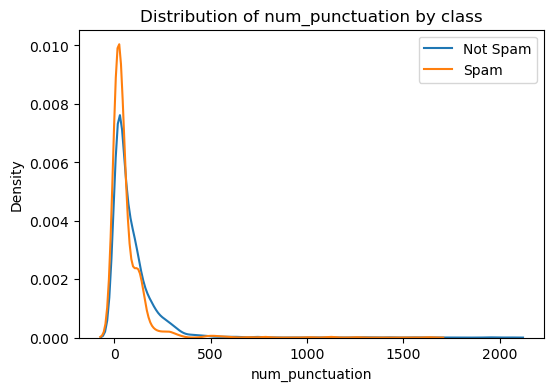

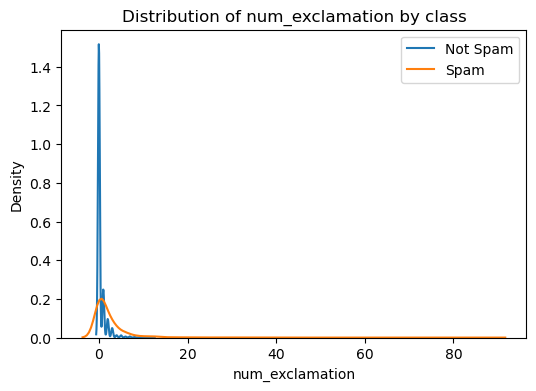

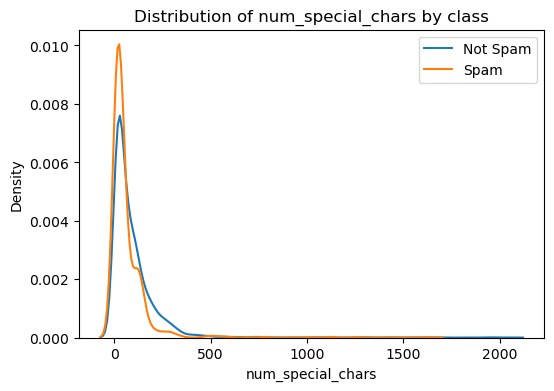

In [11]:
for feat in features_to_plot:
    plt.figure(figsize=(6,4))
    sns.kdeplot(df[df['spam']==0][feat], label='Not Spam')
    sns.kdeplot(df[df['spam']==1][feat], label='Spam')
    plt.title(f'Distribution of {feat} by class')
    plt.legend()
    plt.show()

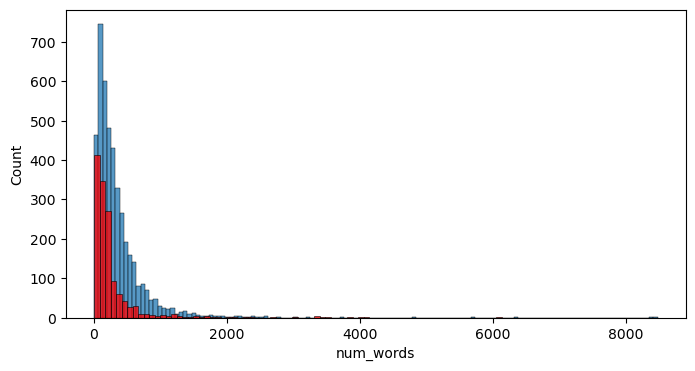

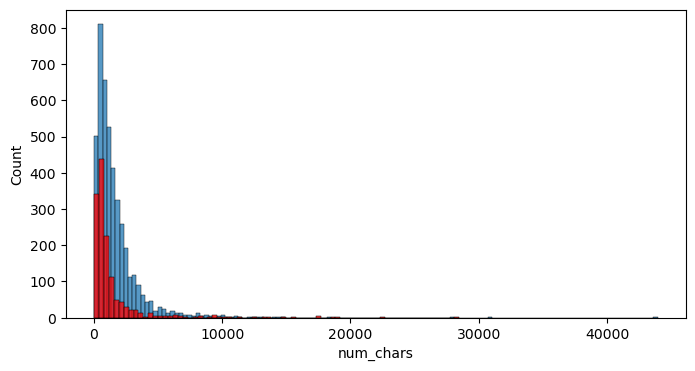

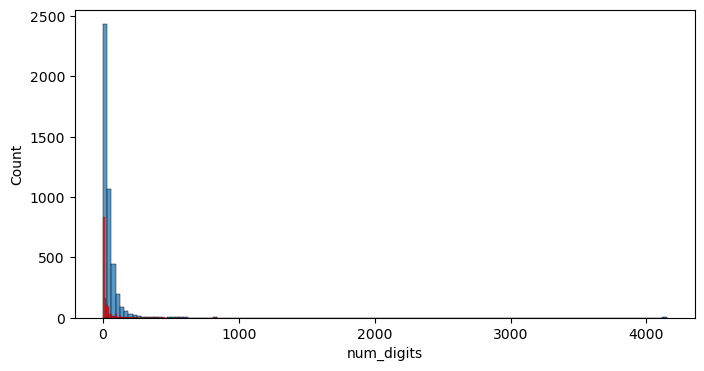

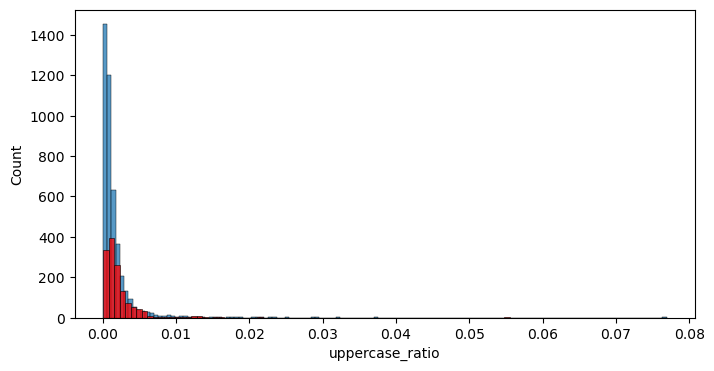

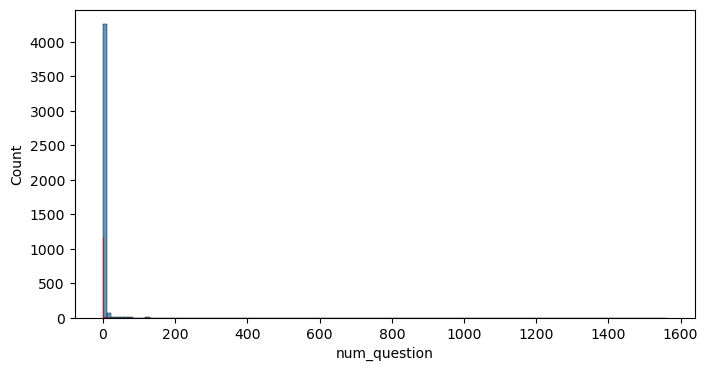

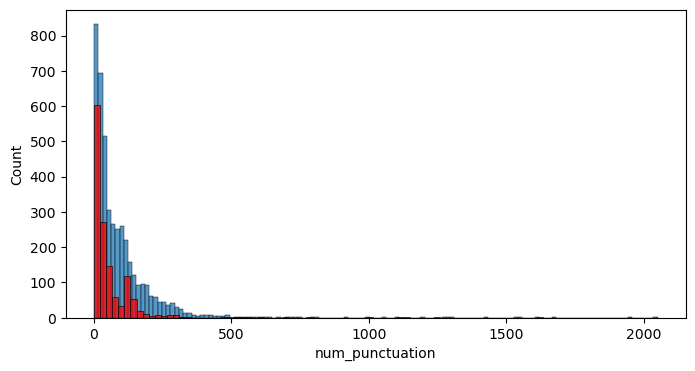

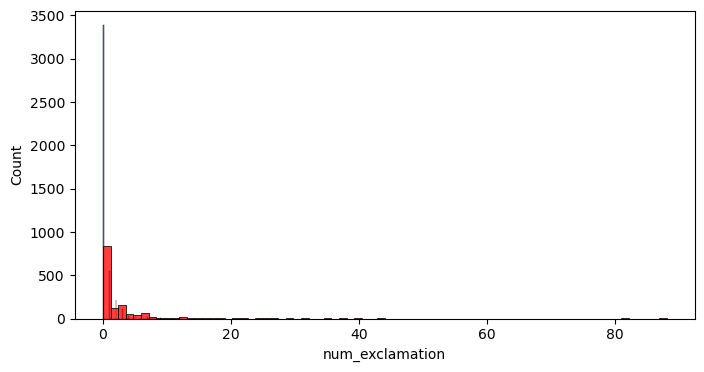

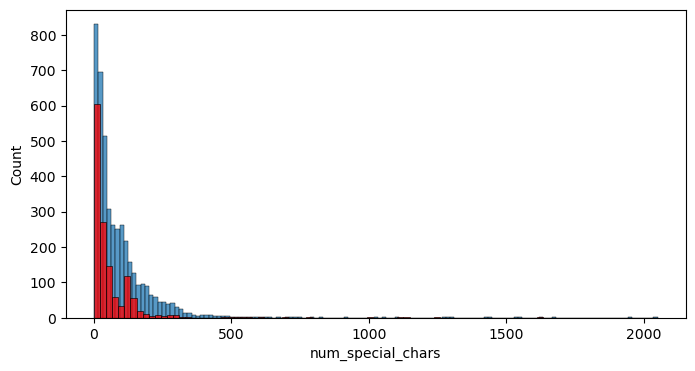

In [12]:
for feat in features_to_plot:
    plt.figure(figsize=(8,4))
    sns.histplot(df[df['spam']==0][feat])
    sns.histplot(df[df['spam']==1][feat],color='red')
    plt.show()

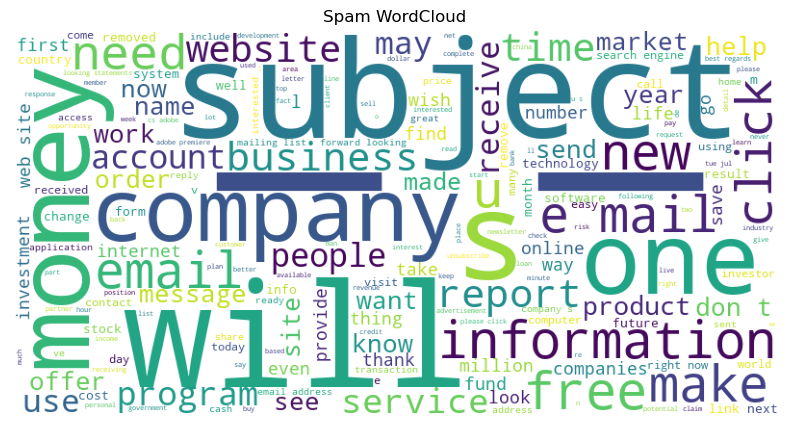

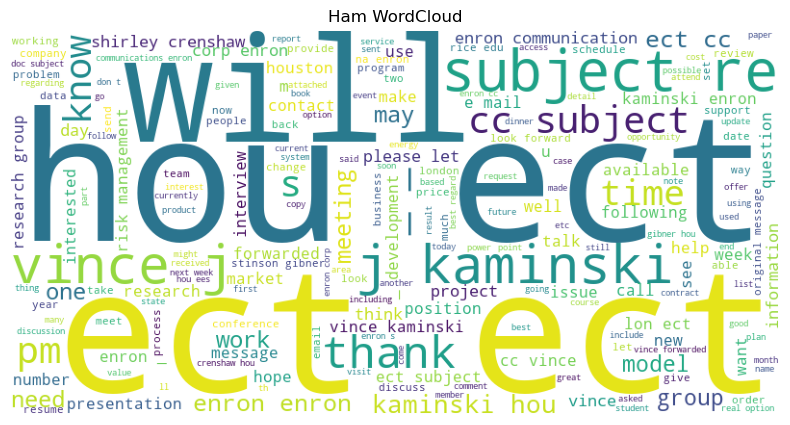

In [13]:
spam_text = " ".join(df[df['spam'] == 1]['text'].str.lower())

wc_spam = WordCloud(
    width=800,
    height=400,
    background_color='white',
    # colormap='Reds'
).generate(spam_text)

plt.figure(figsize=(10,5))
plt.imshow(wc_spam)
plt.axis("off")
plt.title("Spam WordCloud")
plt.show()

ham_text = " ".join(df[df['spam'] == 0]['text'].str.lower())

wc_ham = WordCloud(
    width=800,
    height=400,
    background_color='white',
    # colormap='Reds'
).generate(ham_text)

plt.figure(figsize=(10,5))
plt.imshow(wc_ham)
plt.axis("off")
plt.title("Ham WordCloud")
plt.show()

In [14]:
print("Train set size:", X_train.shape)
print("Test set size:", X_val.shape)
print("Test set size:", X_test.shape)
print(np.mean(X_train, axis=0))
print(np.std(X_train, axis=0))

print(np.mean(X_val, axis=0))
print(np.std(X_val, axis=0))

Train set size: (3665, 3009)
Test set size: (917, 3009)
Test set size: (1146, 3009)
[ 1.17930052e-02  2.21962404e-03  2.42531961e-03 ...  1.18383399e-16
  4.42877507e-17 -2.80206357e-17]
[0.04090053 0.01743158 0.01983577 ... 1.         1.         1.        ]
[ 0.01175503  0.00120263  0.00408433 ... -0.00890167 -0.02687075
 -0.03353765]
[0.04230125 0.01117712 0.02835577 ... 0.91637622 0.59593822 0.79770453]


# Model and Training

> ## Testing different models

In [16]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

models_params = {

    # "Logistic Binary": {
    #     "model": LogisticRegression(solver='liblinear', max_iter=1000, class_weight=None),
    #     "model_balanced": LogisticRegression(solver='liblinear', max_iter=1000, class_weight='balanced'),
    #     "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l2']}
    # },
    # "Logistic Multinomial": {
    #     "model": LogisticRegression(multi_class='multinomial', solver='saga', max_iter=1000, class_weight=None),
    #     "model_balanced": LogisticRegression(multi_class='multinomial', solver='saga', max_iter=1000, class_weight='balanced'),
    #     "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l2']}
    # },
    # "Robust Logistic": {
    #     "model": LogisticRegression(solver='saga', max_iter=1000, class_weight=None),
    #     "model_balanced": LogisticRegression(solver='saga', max_iter=1000, class_weight='balanced'),
    #     "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l1']}
    # },

    "Logistic Regression CV": {
        "model": LogisticRegressionCV(cv=5, max_iter=1000, scoring='f1', solver='lbfgs', class_weight=None),
        "model_balanced": LogisticRegressionCV(cv=5, max_iter=1000, scoring='f1', solver='lbfgs', class_weight='balanced'),
        "params": {}
    },

    "Gaussian NB": {"model": GaussianNB(), "params": {}},
    "Bernoulli NB": {"model": BernoulliNB(), "params": {}},

    "LDA (GDA)": {
        "model": LinearDiscriminantAnalysis(),
        "params": {"shrinkage": [None, 'auto'], "solver": ['svd', 'lsqr']}
    },
    "QDA": {"model": QuadraticDiscriminantAnalysis(), "params": {}},

    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {
            "n_neighbors": [3, 5, 7, 11],
            "weights": ["uniform", "distance"],
            "metric": ["euclidean", "manhattan"]
        }
    },

    "SVM": {
        "model": SVC(probability=True, class_weight=None),
        "model_balanced": SVC(probability=True, class_weight='balanced'),
        "params": {
            "C": [0.1, 1, 10],
            "kernel": ["linear", "rbf"],
            "gamma": ["scale", "auto"]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(random_state=42, class_weight=None),
        "model_balanced": RandomForestClassifier(random_state=42, class_weight='balanced'),
        "params": {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=42),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.01, 0.1],
            "max_depth": [3, 5]
        }
    },

    "XGBoost": {
        "model": XGBClassifier(
            use_label_encoder=False,
            eval_metric="logloss",
            random_state=42
        ),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.01, 0.1],
            "max_depth": [3, 6],
            "subsample": [0.8, 1],
            "colsample_bytree": [0.8, 1]
        }
    }
}

results = []

for name, mp in models_params.items():
    model_variants = [("normal", mp["model"])]
    if "model_balanced" in mp:
        model_variants.append(("balanced", mp["model_balanced"]))

    for variant_name, model in model_variants:
        print(f"\n=== Training {name} ({variant_name}) ===")
        param_grid = mp.get("params", {})

        if param_grid:
            grid = GridSearchCV(model, param_grid, cv=5, scoring='f1', n_jobs=-1)
            grid.fit(X_train, y_train)
            best_model = grid.best_estimator_
        else:
            best_model = model
            best_model.fit(X_train, y_train)

        y_pred = best_model.predict(X_val)
        val_accuracy = accuracy_score(y_val, y_pred)
        val_f1 = f1_score(y_val, y_pred)

        try:
            val_roc_auc = roc_auc_score(y_val_main, best_model.predict_proba(X_val)[:,1])
        except:
            val_roc_auc = None

        results.append({
            "Model": name,
            "Variant": variant_name,
            "Best_Params": best_model.get_params() if hasattr(best_model, "get_params") else None,
            "Accuracy": val_accuracy,
            "F1": val_f1,
            "ROC-AUC": val_roc_auc
        })


=== Training Logistic Regression CV (normal) ===

=== Training Logistic Regression CV (balanced) ===

=== Training Gaussian NB (normal) ===

=== Training Bernoulli NB (normal) ===

=== Training LDA (GDA) (normal) ===


/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
5 fits failed out of a total of 20.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/discriminant_analysis.py", lin


=== Training QDA (normal) ===


/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/arrow/anaconda3/lib/python3.13/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(



=== Training KNN (normal) ===

=== Training SVM (normal) ===

=== Training SVM (balanced) ===

=== Training Random Forest (normal) ===

=== Training Random Forest (balanced) ===

=== Training Gradient Boosting (normal) ===

=== Training XGBoost (normal) ===


/home/arrow/anaconda3/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [23:30:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/arrow/anaconda3/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [23:30:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/arrow/anaconda3/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [23:30:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/arrow/anaconda3/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [23:30:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/arrow/anac

Results:
                     Model   Variant  \
1   Logistic Regression CV  balanced   
0   Logistic Regression CV    normal   
8                      SVM  balanced   
7                      SVM    normal   
4                LDA (GDA)    normal   
10           Random Forest  balanced   
12                 XGBoost    normal   
11       Gradient Boosting    normal   
9            Random Forest    normal   
2              Gaussian NB    normal   
6                      KNN    normal   
5                      QDA    normal   
3             Bernoulli NB    normal   

                                          Best_Params  Accuracy        F1  \
1   {'Cs': 10, 'class_weight': 'balanced', 'cv': 5...  0.992366  0.984055   
0   {'Cs': 10, 'class_weight': None, 'cv': 5, 'dua...  0.990185  0.979215   
8   {'C': 10, 'break_ties': False, 'cache_size': 2...  0.985823  0.970115   
7   {'C': 10, 'break_ties': False, 'cache_size': 2...  0.985823  0.970115   
4   {'covariance_estimator': None, 'n_compone

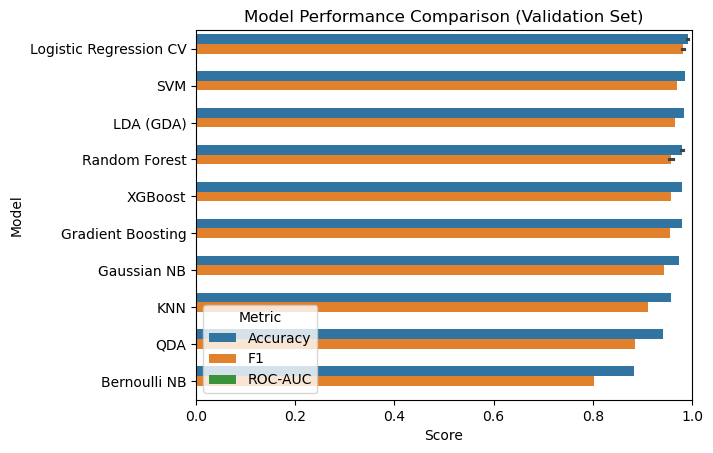

Best model based on F1-score: Logistic Regression CV balanced


In [17]:
# Results
results_df = pd.DataFrame(results).sort_values(by='F1', ascending=False)
print("Results:")
print(results_df)

# Graph comparaison
results_melted = results_df.melt(id_vars=["Model"], value_vars=["Accuracy","F1","ROC-AUC"], 
                                 var_name="Metric", value_name="Score")

sns.barplot(x="Score", y="Model", hue="Metric", data=results_melted)
plt.title("Model Performance Comparison (Validation Set)")
plt.xlim(0,1)
plt.show()

# Select the best model
best_model_name = results_df.sort_values("F1", ascending=False).iloc[0]["Model"]
best_model_variant = results_df.sort_values("F1", ascending=False).iloc[0]["Variant"]
print("Best model based on F1-score:", best_model_name, best_model_variant)
final_model = models_params[best_model_name]["model"]

In [18]:
final_model.fit(X_train, y_train)

# Predict on the preprocessed train set
y_pred = final_model.predict(X_train) 

accuracy = accuracy_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)
roc_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:,1])
print(f'Train Accuracy : {accuracy:.4%}')
print(f'Train F1-score : {f1:.4%}')
print(f'Train ROC-AUC : {roc_auc:.4%}')


# Predict on the preprocessed test set
y_pred = final_model.predict(X_test) 

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, best_model.predict_proba(X_test)[:,1])
print(f'\nAccuracy : {accuracy:.4%}')
print(f'F1-score : {f1:.4%}')
print(f'ROC-AUC : {roc_auc:.4%}')

Train Accuracy : 100.0000%
Train F1-score : 100.0000%
Train ROC-AUC : 99.9996%

Accuracy : 98.8656%
F1-score : 97.6234%
ROC-AUC : 99.6342%
